# Micro-ring resonator

Micro-ring resonator on silicon-on-insulator (SOI). Compare with [Lumerical example](https://optics.ansys.com/hc/en-us/articles/360042800293-Ring-resonator-getting-started-Design-and-initial-simulation): our results appear more accurate (higher Q and no splitting artifact) and run faster

[Run in Lumi Colab](https://colab.luminescentai.com/hub/user-redirect/lab/tree/tutorials/photonic_circuits/ring/ring.ipynb)

## Parameters

Mesh is not watertight; plotting debug view


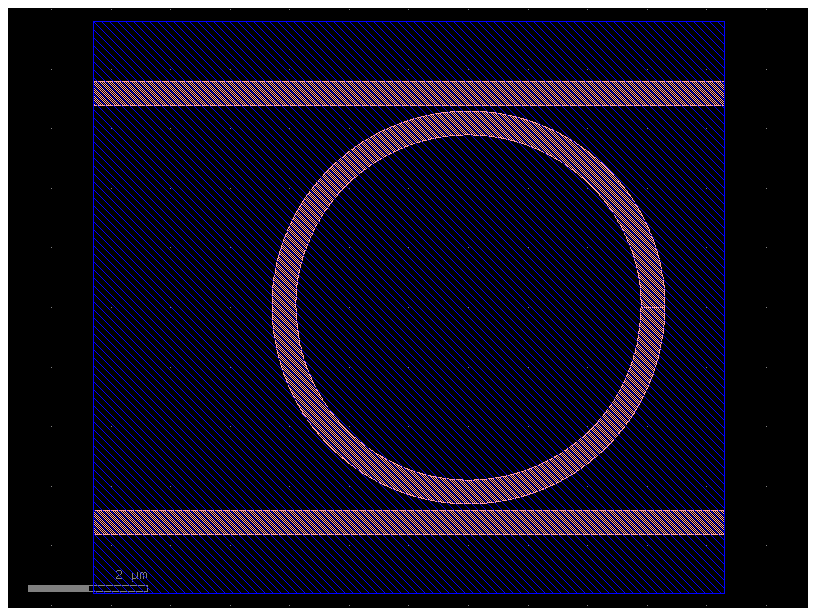

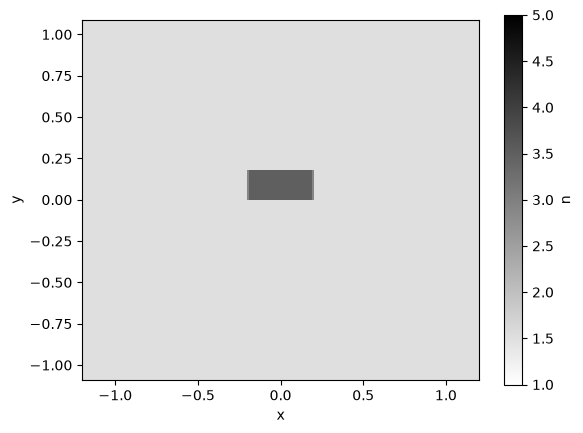

using simulation folder runs/ring


In [ ]:
import os
import numpy as np
import matplotlib.pyplot as plt

import gdsfactory as gf
from gdsfactory.technology import LogicalLayer, LayerLevel, LayerStack
import luminescent as lumi

# simulation folder
path = os.path.join("runs", "ring")

# length units are arbitrary so long as they are consistent, in this case [um]. everything gets normalized around origin wavelength and period at backend.
wavelength = 1.55  # characteristic wavelength [um]
bandwidth = 0.1  # wavelength bandwidth [um]
wavelengths = np.linspace(wavelength - bandwidth / 2, wavelength + bandwidth / 2, 401)

# horizontal dims
r = 3.1  # radius of ring
w_wg = 0.4  # width of waveguide
gap = 0.1  # gap between waveguide and ring

# vertical dims
h_wg = 0.18  # height of waveguide

def setup(path,r,gap,w_wg,h_wg):
    # simulation parameters
    nres = 8  # number of grid points per wavelength in material (not vacuum)
    shutoff = 0.001
    courant = 0.95  # Courant factor for time step size, relative to max allowed by grid
    subpixel_smoothing = 1
    PML_decay = [.001,.1,.1]
    tmax = 3000  # max time [periods]
    shot_every = 50  # save and plot field every _ periods, involves slow disk write
    views = [lumi.view("Hz", x=0, z=0)]

    boundaries = ['PML', 'PML', 'PML']
    
    # margins
    source_offset = 2
    margin = 1 

    # vertical dims
    zmargin = height_port_margin = 1 
    zmin = -h_wg / 2 - zmargin
    zmax = h_wg / 2 + zmargin

    # materials
    core = 'Si'
    clad = 'SiO2'
    background = clad
    nSi = 3.5
    nSiO2 = 1.5
    materials = {
        'Si': lumi.material(nSi),
        'SiO2': lumi.material(nSiO2),
    }

    # layer stack
    WG = (1, 0)  # waveguide layer
    BBOX = (10, 0)  # bounding box layer
    layer_stack = LayerStack(
        layers={
            'core': LayerLevel(
                layer=LogicalLayer(layer=WG),
                thickness=h_wg,
                zmin=-h_wg / 2,
                material=core,
                mesh_order=1,
            )    })

    ## Geometry
    # add-drop ring: input o1, drop o2, through o3, add o4
    # make component in gdsfactory. alternatively, you can import .gds layout into gdsfactory or .stl bodies directly into ours
    c = gf.Component()

    c << gf.components.ring(radius=r, width=w_wg, layer=WG)

    l = 2 * r + 2 * margin + w_wg
    # s = c << gf.components.straight(length=l - source_offset, width=w_wg)
    # s.move((-l / 2 + source_offset, w_wg + gap + r))

    # s1 = c << gf.components.straight(length=source_offset, width=w_wg)
    # s1.connect('o2', s.ports['o1'])

    # top waveguide: one straight, extended by source_offset on left for source
    y_top = w_wg + gap + r
    s = c << gf.components.straight(length=l + source_offset, width=w_wg)
    s.move((-l / 2 - source_offset, y_top))

    # s2 = c << gf.components.straight(length=l, width=w_wg)
    # s2.move((-l / 2, -(w_wg + gap + r)))
    # bottom waveguide: same extent as top so both ends reach bbox edge
    s2 = c << gf.components.straight(length=l + source_offset, width=w_wg)
    s2.move((-l / 2 - source_offset, -y_top))

    # c.add_port('o1', port=s.ports['o1'])
    c.add_port('o1', center=(-l / 2, y_top), width=w_wg, orientation=180, layer=WG)  # margin from ring edge
    # c.add_port('o2', port=s2.ports['o1'])
    c.add_port('o2', center=(-l / 2, -y_top), width=w_wg, orientation=180, layer=WG)
    c.add_port('o3', port=s.ports['o2'])
    c.add_port('o4', port=s2.ports['o2'])
    c << gf.components.bbox(component=c, layer=BBOX, top=margin, bottom=margin)
    c.plot()

    bbox = c.bbox_np().tolist()
    bbox[0].append(zmin)
    bbox[1].append(zmax)

    # source and modes setup
    w_port = w_wg + 2 * margin

    frames = [
        lumi.plane_frame('mode', wls_mode_solver=[wavelength], start=[-w_port / 2, zmin], stop=[w_port / 2, zmax], boundaries=['PML', 'PML'], nmodes=1),  # local xy basis
        lumi.points_frame('trace', points=[[0,0]], time_domain=True),
    ]

    sources = [lumi.gf_source('o1', c, layer_stack, source_offset, frame='mode', wl=wavelength, bandwidth=max(max(wavelengths) - min(wavelengths), wavelength / 8))]

    monitors = [
        lumi.gf_monitor('o1', c, layer_stack, frame='mode'),
        lumi.gf_monitor('o2', c, layer_stack, frame='mode'),
        lumi.gf_monitor('o3', c, layer_stack, frame='mode', mirrored=True),
        lumi.gf_monitor('o1', c, layer_stack, frame='trace', name='u1')
    ]

    lumi.mesh(path, c, layer_stack, materials, zmin, zmax)
    lumi.setup(
        path=path,
        wl=wavelength,
        wls=wavelengths,
        materials=materials,
        background=background,
        boundaries=boundaries,
        bbox=bbox,
        # 
        frames=frames,
        sources=sources,
        monitors=monitors,
        # 
        nres=nres,
        courant=courant,
        subpixel_smoothing=subpixel_smoothing,
        tmax=tmax,
        PML_decay=PML_decay,
        # 
        views=views,
        shot_every=shot_every,
        shutoff=shutoff,
        
    )

setup(path,r,gap,w_wg,h_wg)

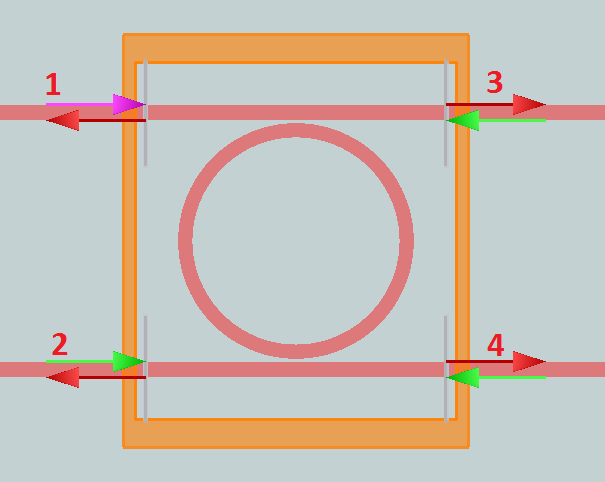

## Solve

In [11]:
lumi.solve(path)

backend using simulation folder runs/ring
setting up simulation...
processing geometry bodies...
generating voxels...
voxelation: 6.531373 seconds (219.61 M allocations: 8.293 GiB, 23.04% gc time, 293.85% compilation time)
Yee mode λ=1.0: neff 2.1167
making sources o1 ...
making monitors o1 o2 o3 u1 ...
run: runs/ring
processor: GPU
cpu threads: 48

nres: 8.0
courant: 0.95
subpixel_smoothing: 1
  
boundaries: [:PML :PML; :PML :PML; :PML :PML]

sources
   o1: -6.3, 3.6, -0.09 

monitors
   o1: -4.3, 3.6, -0.09 
   o2: -4.3, -3.6, -0.09 
   o3: 4.3, 3.6, -0.09 
   u1: -4.3, 3.6, -0.09 

original size: (194, 166, 33)
padded size: (262, 184, 54)
cell count: 2,603,232

step size: 54.0 steps/period
source duration: 3.94 periods

max time: 3,000 periods
max steps: 162,000
max load: 421,723,584,000 cell-steps
energy decay threshold: 0.001

running simulation...
accumulating dft field...
period 50, decay: 0.183, 0.269 seconds/period, 522.38 Mcells/s
period 100, decay: 0.07, 0.019 seconds/period

## Movie

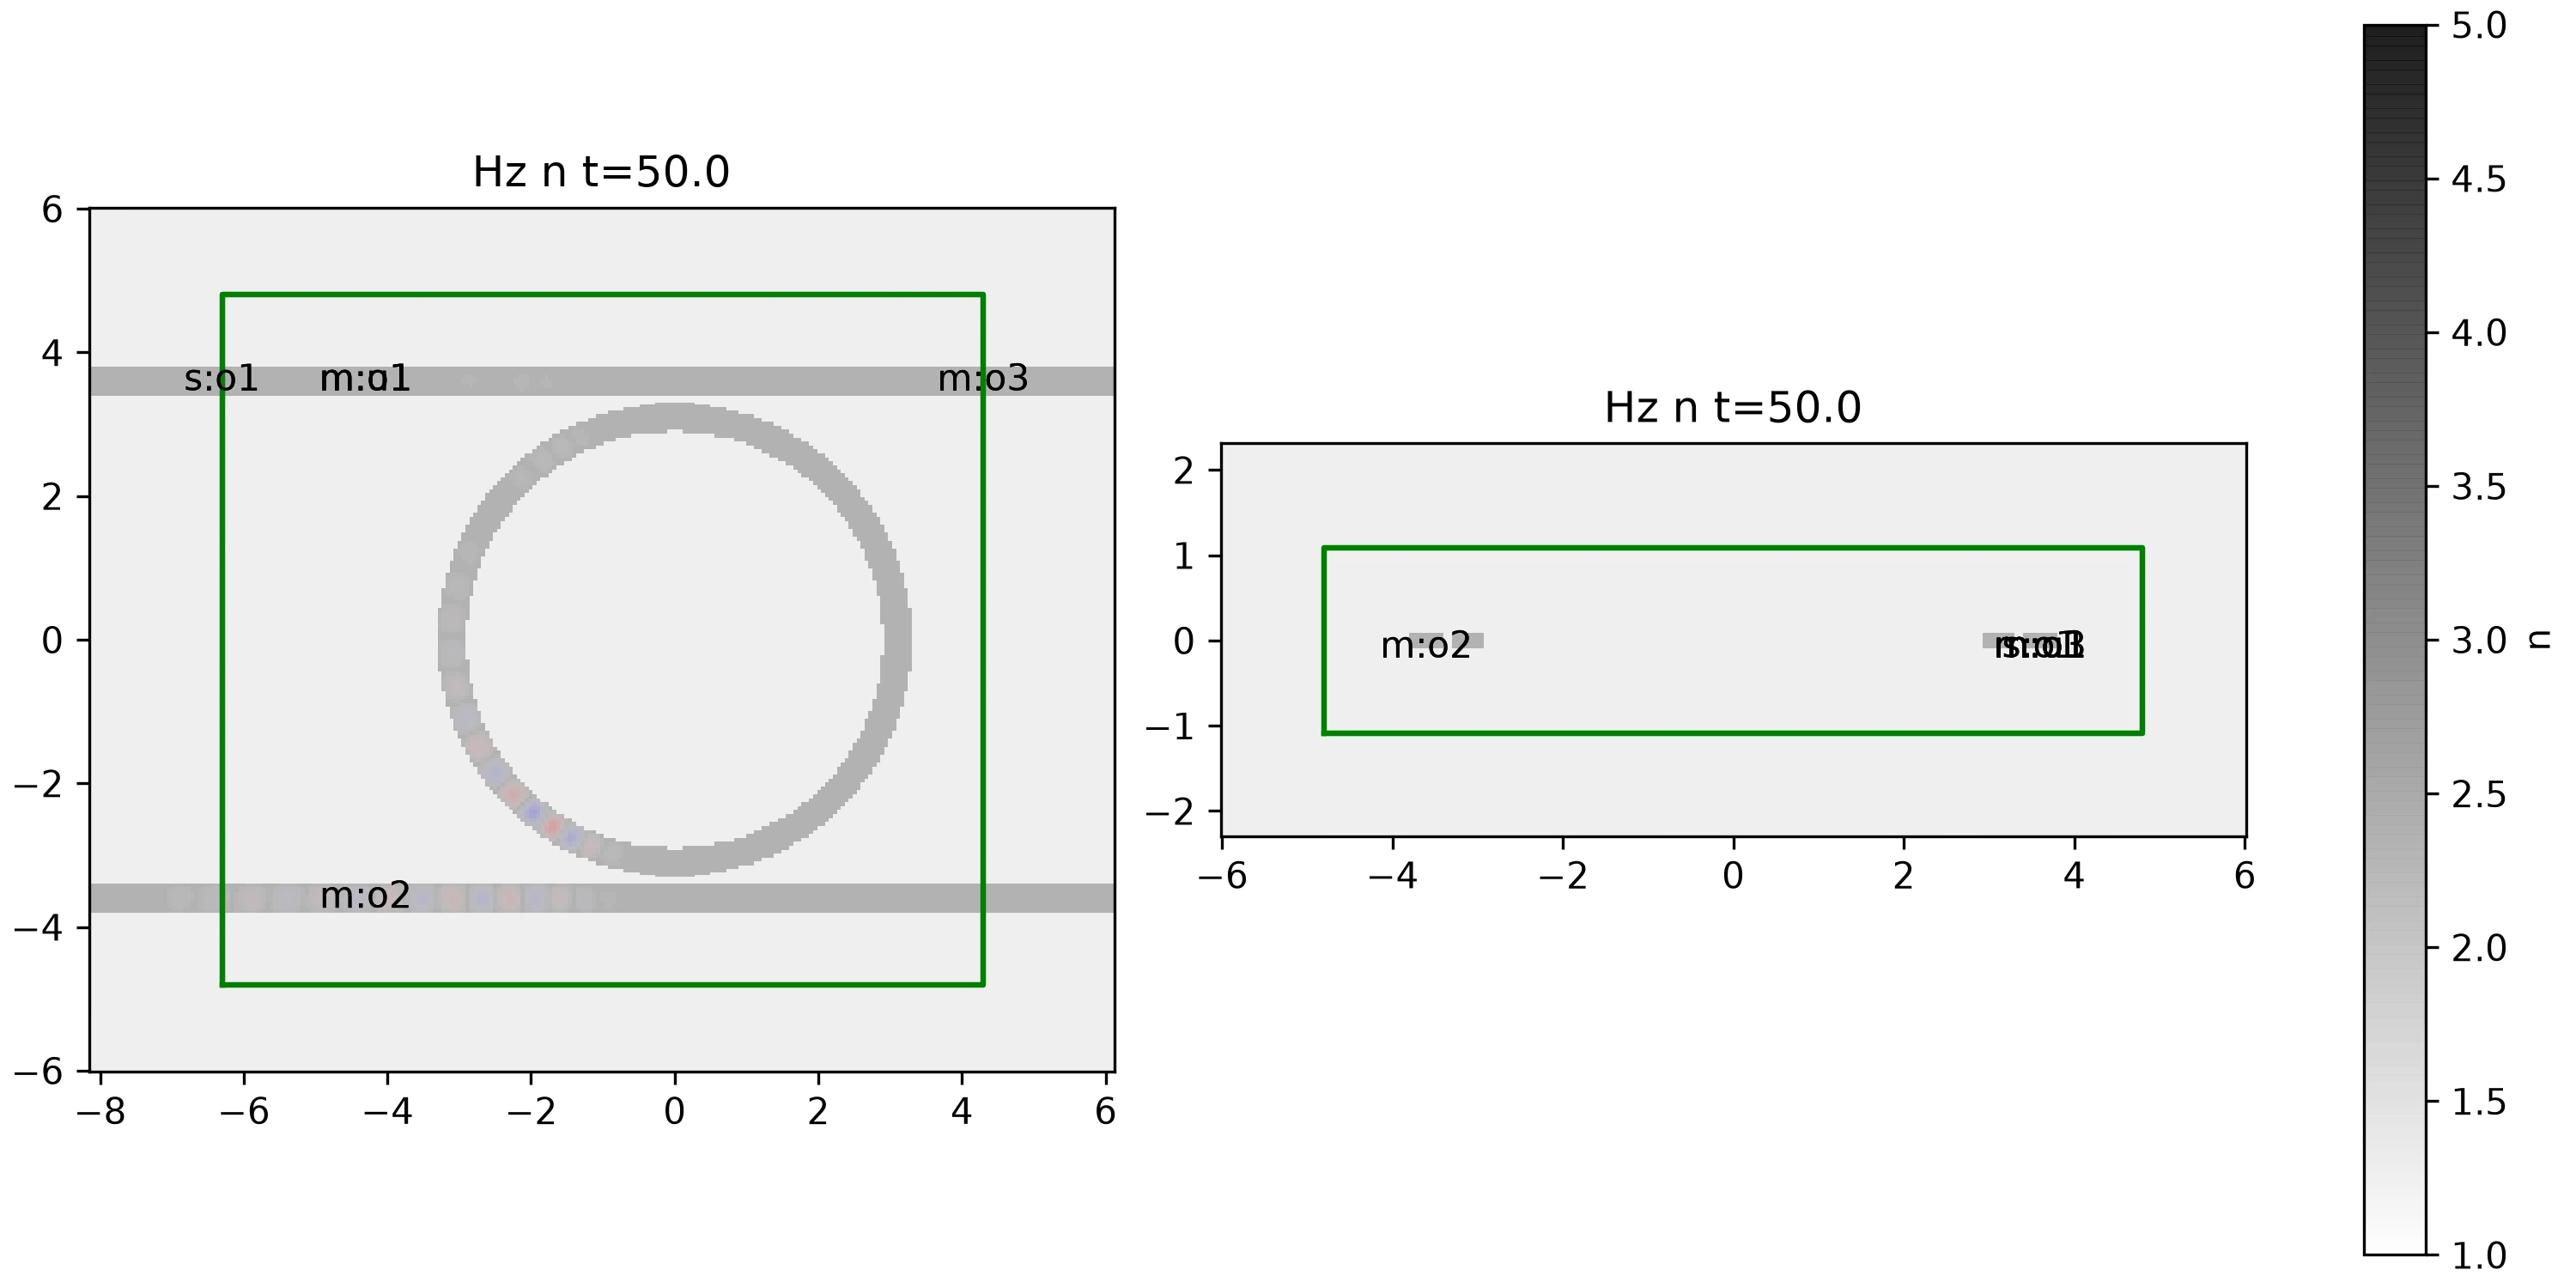

In [12]:
lumi.movie(path)

## Results


### S parameters

loading solution from runs/ring
may take a minute if simulation folder is remotely mounted


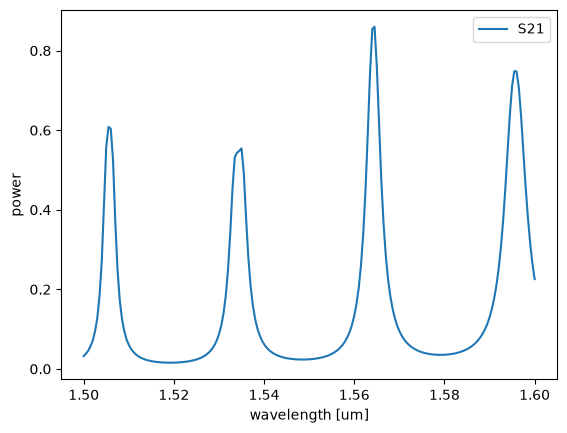

In [13]:
sol = lumi.load(path)
o1=sol['monitors']['o1']
o2=sol['monitors']['o2']
o3=sol['monitors']['o3']

S21 = o2['modes'][0]['+'] / o1['modes'][0]['-'] # drop port
S31 = o3['modes'][0]['+'] / o1['modes'][0]['-'] # through port

plt.plot(wavelengths, np.abs(S21)**2, label="S21")
# plt.plot(wavelengths, S31, label="S31")

plt.xlabel("wavelength [um]")
plt.ylabel("power")
plt.legend()
plt.show()

### Resonances

In [14]:
from scipy.signal import find_peaks

dw=bandwidth/len(wavelengths)
I, props = find_peaks(np.abs(S21), height=0.4, distance=.01//dw)

peaks = wavelengths[I]
print(f'Peaks: {", ".join(f"{1000*x:.2f}nm" for x in peaks)}')

Peaks: 1505.50nm, 1535.00nm, 1564.50nm, 1595.50nm


### FSR

In [15]:
FSR = np.mean(np.diff(peaks))
print(f'FSR: {1000*FSR:.2f}nm')

FSR: 30.00nm


### Q factor (FWHM method)

In [16]:
i=len(I)//2
mid = I[i]
y=np.abs(S21)**2   # power: FWHM is the half-power (-3 dB) width
half = y[mid]/2

l = mid
while y[l] > half: l -= 1
wl_lo = np.interp(half, [y[l], y[l+1]], [wavelengths[l], wavelengths[l+1]])

r = mid
while y[r] > half: r += 1
wl_hi = np.interp(half, [y[r], y[r-1]], [wavelengths[r], wavelengths[r-1]])  # np.interp needs increasing y

FWHM = wl_hi - wl_lo
wl=wavelengths[mid]
Q=wl/FWHM
print(f'FWHM: {1000*FWHM:.2f}nm\nQ factor (FWHM method): {Q:.0f}')

FWHM: 3.80nm
Q factor (FWHM method): 412


## Early stopping (optional)

Can still get FSR and Q factor by stopping early. Saves time because high Q cavity takes long time to decay completely. Instead simulate for only long enough for resonances to settle into decay trend. Here, can set `shutoff=0.1` 

Stopping early in time domain convolves sinc blur in frequency domain. Can still extract resonances and FSR from blurred spectrum, but Q factor must be computed from time domain decay signal.

### Q factor (time domain decay method)

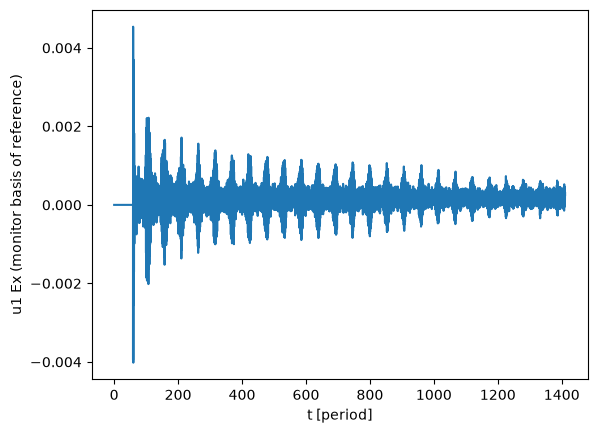

In [17]:
t = np.array(sol['t'])
y = np.array(sol['monitors']['u1']['fields']['Ex'][0,:])
t = t[:len(y)]

# zero transients before t0, leaving only ring decay:
# the source pulse peaks at the monitor, then takes ~its duration (~4 periods here) to pass
t0 = t[np.argmax(np.abs(y))] + 4
i = np.searchsorted(t, t0)
y[:i] = 0

plt.plot(t, y)
plt.xlabel("t [period]")
plt.ylabel("u1 Ex (monitor basis of reference)")
plt.show()

In [18]:
import subprocess

# harmonic inversion of the ringdown (needs harminv: sudo apt install harminv)
# time is in periods of `wavelength`, so frequency f = wavelength / λ
fmin, fmax = wavelength / wavelengths[-1], wavelength / wavelengths[0]
dt = t[1] - t[0]
out = subprocess.run(["harminv", "-t", str(dt), f"{fmin}-{fmax}"],
                     input="\n".join(map(str, y[i:])), capture_output=True, text=True).stdout

# columns: frequency, decay constant, Q, |amplitude|, phase, error
for line in out.splitlines()[1:]:
    f, decay, Q, amp, phase, err = map(float, line.split(","))
    if fmin <= f <= fmax:
        print(f"{1000 * wavelength / f:.2f}nm   Q = {Q:.0f}   |amp| = {amp:.2g}   error = {err:.1e}")


1596.20nm   Q = 341   |amp| = 0.00033   error = 1.4e-06
1595.19nm   Q = 337   |amp| = 0.0004   error = 2.0e-06
1577.95nm   Q = 476   |amp| = 6.9e-07   error = 1.1e-03
1564.81nm   Q = 486   |amp| = 0.00016   error = 2.0e-06
1534.53nm   Q = 664   |amp| = 0.00015   error = 3.0e-07
1506.17nm   Q = 807   |amp| = 8e-05   error = 2.5e-06
1505.16nm   Q = 797   |amp| = 0.00012   error = 2.5e-06
1501.11nm   Q = 232   |amp| = 9.5e-06   error = 3.3e-05
